In [85]:
import matplotlib.pyplot as plt
import h5py
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import cfgrib
# import fonctions as funcs

import sys
from math import radians, sin, cos, sqrt, atan2
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
from pyproj import Geod
import numpy as np
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch
from tools import *
from seabird.cnv import fCNV
from adjustText import adjust_text
import gsw
import glidertools as gt

In [86]:
def dm_to_dd(deg, minutes, west=False, south=False):
    """Convert degrees/minutes to decimal degrees."""
    dd = float(deg) + float(minutes) / 60.0
    if west or south:
        dd *= -1
    return dd

def get_next_value(values, key):
    for i, v in enumerate(values):
        if isinstance(v, str) and v.strip().startswith(key):
            if i + 1 < len(values):
                return values[i + 1]
    return None


def haversine(lon1, lat1, lon2, lat2):
    R = 6371  # km
    dlon = radians(lon2 - lon1)
    dlat = radians(lat2 - lat1)

    a = sin(dlat/2)**2 + cos(radians(lat1))*cos(radians(lat2))*sin(dlon/2)**2
    return 2 * R * atan2(sqrt(a), sqrt(1 - a))


def assign_stations(casts, threshold_km=2):
    station_id = 1
    station_letters = {}

    prev_lon = None
    prev_lat = None
    letter_counter = {}

    for i, c in enumerate(casts):

        if i == 0:
            c["station_number"] = station_id
            letter_counter[station_id] = 0
            c["station_id"] = f"{station_id}a"
            prev_lon, prev_lat = c["lon_start"], c["lat_start"]
            continue

        dist = haversine(prev_lon, prev_lat, c["lon_start"], c["lat_start"])

        if dist < threshold_km:
            # same station
            c["station_number"] = station_id
        else:
            station_id += 1
            c["station_number"] = station_id
            letter_counter[station_id] = 0

        # station letter (a, b, c...)
        letter_counter[c["station_number"]] += 1
        letter = chr(96 + letter_counter[c["station_number"]])  # a,b,c...

        c["station_id"] = f"{c['station_number']}{letter}"

        prev_lon, prev_lat = c["lon_start"], c["lat_start"]

    return casts


def save_to_nc(casts, outfile="ctd_metadata.nc"):

    n = len(casts)

    ds = xr.Dataset(
        data_vars=dict(
            station_number=("cast", [c["station_number"] for c in casts]),
            cast_id=("cast", [c["cast_id"] for c in casts]),
            depth=("cast", [c["depth"] for c in casts]),

            lon_start=("cast", [c["lon_start"] for c in casts]),
            lat_start=("cast", [c["lat_start"] for c in casts]),
            lon_end=("cast", [c["lon_end"] for c in casts]),
            lat_end=("cast", [c["lat_end"] for c in casts]),
            # time_start = ("cast", [c["time_start"] for c in casts]),
            # time_end = ("cast", [c["time_end"] for c in casts]),
        ),
        coords=dict(
            cast=np.arange(n),
            station_id=("cast", [c["station_id"] for c in casts]),
            time_start=("cast", [c["time_start"] for c in casts]),
            time_end=("cast", [c["time_end"] for c in casts]),
        )
    )

    ds.to_netcdf(outfile)
    print(f"Saved: {outfile}")

def det_max_depth(pres):
    if pres < 600:
        return 300
    elif pres < 1500:
        return 1200
    else:
        return 5000
    
# Function to plot all lines and collect handles
def plot_profiles(current_ax, x_data, y_data, gl_x_col, plot_dives, legend_times, gl, dc, is_main_plot=False):
    # Ship CTD (Black line) - Only labeled on the main plot for legend collection
    # current_ax.plot(x_data, y_data, 'k', lw=4)
    ship_line, = current_ax.plot(x_data, y_data, '0.5', lw=3)
    
    # Glider Profiles
    glider_handles = []
    for i, ind in enumerate(plot_dives):
        # Use a label only if it's the main plot for legend handles
        label_text = legend_times[i] if is_main_plot else None 
        print("Plotting glider line")
        print(gl[gl_x_col].where(gl.dives == ind).shape)
        glider_line, = current_ax.plot(
            gl[gl_x_col].where(gl.dives == ind), 
            -gl.ctd_pressure.where(gl.dives == ind), 
            c=dc[i], 
            lw=2, 
            label=label_text
        )
        if is_main_plot:
            glider_handles.append(glider_line)
    
    if is_main_plot:
        # Return ship handle and all glider handles
        return [ship_line] + glider_handles
    return None # Return None for inset/salinity plots

def grid_seaglider(gl, bin_edges, exclude_vars=None):
    """
    Bin Seaglider data in pressure using the existing 'dives' profile labels.
    
    Parameters
    ----------
    gl : xarray.Dataset
        Must contain 'ctd_pressure' and 'dives'.
    bin_edges : array-like
        Pressure bin edges (e.g., np.arange(0, 1001, 1)).
    exclude_vars : list
        Variables that should not be binned.
    
    Returns
    -------
    xr.Dataset
        Binned data with dimensions: pressure x profile
    """

    import numpy as np
    import xarray as xr

    # -------------------------------------------------------
    # Basic checks
    # -------------------------------------------------------
    if "ctd_pressure" not in gl:
        raise KeyError("Dataset must contain 'ctd_pressure'.")
    if "dives" not in gl:
        raise KeyError("Dataset must contain 'dives'.")

    # Default excluded variables
    if exclude_vars is None:
        exclude_vars = ["ctd_time", "ctd_time_dt64"] #"longitude", "latitude"

    # Identify data variables to bin
    data_vars = [v for v in gl.data_vars if v not in exclude_vars and v not in ["ctd_pressure", "dives", "ctd_time_dt64"]]
    data_vars = data_vars + [v for v in gl.coords if v not in ["ctd_time_dt64"]]
    
    # Compute bin centers
    bin_centers = bin_edges[:-1] + np.diff(bin_edges) / 2
    n_bins = len(bin_centers)

    # Unique dive/climb profile IDs
    profiles = np.unique(gl["dives"].values)
    n_profiles = len(profiles)

    # Convert to dataframe for easy grouping
    df = gl.to_dataframe().reset_index()

    # Pre-allocate output arrays
    binned = {
        var: np.full((n_bins, n_profiles), np.nan)
        for var in data_vars
    }

    # -------------------------------------------------------
    # Loop over each profile
    # -------------------------------------------------------
    for i, prof in enumerate(profiles):

        group = df[df["dives"] == prof]
        if group.empty:
            continue

        p = group["ctd_pressure"].values
        bin_idx = np.digitize(p, bin_edges) - 1
        valid = (bin_idx >= 0) & (bin_idx < n_bins)

        # Loop through pressure bins in this profile
        for b in np.unique(bin_idx[valid]):
            mask = bin_idx == b
            if np.any(mask):
                for var in data_vars:
                    binned[var][b, i] = np.nanmedian(group[var].values[mask])

    # -------------------------------------------------------
    # Build xarray output dataset
    # -------------------------------------------------------
    ds_out = xr.Dataset(
        data_vars={f"{var}_binned": (["pressure", "profile"], binned[var]) for var in data_vars},
        coords={
            "pressure": bin_centers,
            "profile": profiles,
        },
        attrs={
            "description": "Seaglider pressure-binned profiles",
            "binning": "median within each pressure bin and dive/climb profile"
        }
    )

    return ds_out

In [87]:
##### POSITION VARIABLES #####
date = '2026-07-06'
ft=10
small_box = False

lon_min, lon_max, lat_min, lat_max = 10, 20, -39, -36
pos_west,pos_east,pos_south,pos_north  = 10, 20, -39,-36  #Reset the area
title=""
vmin_adt = -0.25
vmax_adt = 1.55
# proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

dir_data = "/Volumes/science/MD252_WHIRLS/REP/data/"
dir_figures = "/Volumes/science/MD252_WHIRLS/REP/figures/"
path_nav = "/Volumes/science/MD252_WHIRLS/NAV/"
dir_adcp = dir_data + "SADCP/WHIRLS_NB150_TOT_osite.nc"

sst_path = dir_data + f"SST/BT_masked_Meteosat_{date.replace("-", "")}.nc"
dir_eddies = dir_data + f"Eddies/"
save_fig = dir_figures + f"/L4/"

adt_daily_dir = dir_data + "daily_adt/"

fname_bathy = dir_data + "bathymetry/etopo2.nc"

glider1_path = "/Volumes/science/MD252_WHIRLS/REP/data/GLIDERS/sg283/ncfiles/p2830001.nc"
float1 = (11.54, -37.41)
tosca1 = (11.53, -38.48)

In [88]:
##### Load ADT Data #####
adt_data = nc.Dataset(adt_daily_dir + f"{date}_cmems_data.nc")

lats = adt_data['latitude'][:]
lons = adt_data['longitude'][:]
time = adt_data['time'][:]
adt = adt_data['adt'][:]
ugos = np.squeeze(adt_data['ugos'][:])
vgos = np.squeeze(adt_data['vgos'][:])
current_mag = np.sqrt(ugos**2 + vgos**2)

In [89]:
##### Load CTD Locs #####
ctd_meta_path = '/Volumes/science/MD252_WHIRLS/REP/analysis/ctd_metadata.nc'
ctd = xr.open_dataset(ctd_meta_path)

In [90]:
##### Load Eddies #####
anti, cyc = load_eddies(dir_eddies+date)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:1642: UserWarning: linewidths is ignored by contourf
  result = super().contourf(*args, **kwargs)
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


11.54076 -38.47592


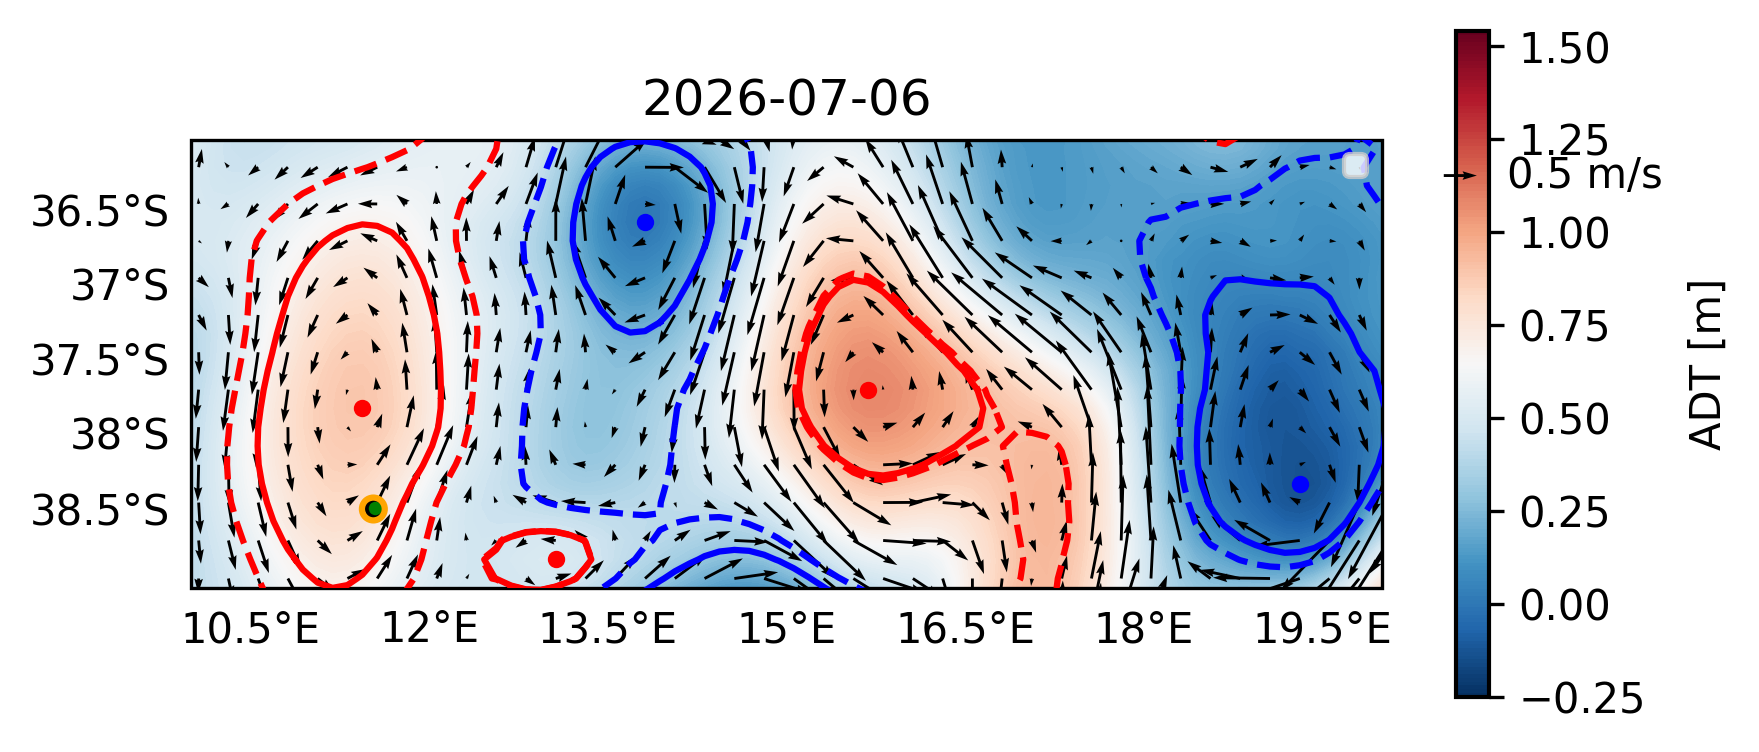

In [91]:

fig = plt.figure(dpi=300)

ax0 = fig.add_subplot(1, 1, 1,projection=proj, zorder=3)
ax0.set_title(f'{date}')
ax0.add_feature(cfeature.LAND,linewidth=0.5,zorder=4, edgecolor='black', facecolor='gray')#,alpha=0.1)
ax0.coastlines(resolution='10m', color='k', linestyle='-', alpha=1,zorder=5)
ax0.set_extent(extent)
map_grid=ax0.gridlines(linewidth=1, color='black', alpha=0.2, linestyle='--', draw_labels=True,zorder=6)
map_grid.top_labels = False
map_grid.left_labels = True
map_grid.right_labels = False
map_grid.xlabel_style = {'size': ft}
map_grid.ylabel_style = {'size': ft}


# ADT contours
c2 = ax0.contourf(lons, lats, adt[0,:,:],  levels=np.arange(vmin_adt, vmax_adt, 0.01), cmap='RdBu_r',
            transform=crs, linestyles='dashed', linewidths=0.7, zorder=2)

# CTD Locs
plotted = set()

texts = []

# for i in range(69):
i = 9
station = int(ctd.station_number.isel(cast=i))

lon = float(ctd.lon_start.isel(cast=i))
lat = float(ctd.lat_start.isel(cast=i))
print(lon, lat)

ax0.scatter(
    lon,
    lat,
    s=18,
    color="green",
    edgecolors="black",
    transform=crs,
    zorder=100,
)

# txt = ax0.text(
#     lon,
#     lat,
#     f"S{station}",
#     fontsize=6,
#     transform=crs,
#     bbox=dict(
#         boxstyle="round,pad=0.1",
#         facecolor="white",
#         edgecolor="none",
#         alpha=0.7,
#     ),
#     zorder=101,
# )

# texts.append(txt)

# adjust_text(
#     texts,
#     ax=ax0,
#     expand_points=(1.2, 1.2),
#     expand_text=(1.2, 1.2),
#     force_text=0.5,
#     force_points=0.5,
# )

# Streamlines
lon_2D, lat_2D = np.meshgrid(lons, lats)
step = 2
Q = ax0.quiver(
    lon_2D[::step, ::step],
    lat_2D[::step, ::step],
    ugos[::step, ::step],
    vgos[::step, ::step],
    transform=crs,
    scale=18, zorder=8)

# Ship path
gx, gy = tosca1
ax0.scatter(
    gx,
    gy,
    s=30,
    facecolors='none',      # Hollow marker
    edgecolors='orange',    # Outline color
    linewidths=1.5,
    transform=crs,
    zorder=100,
)
# ax0.scatter(ship_x, ship_y, s=20, color='green', zorder=100, transform=crs, label="MD Track")
# ax0.scatter(longs_bato[::50],lat_bato[::50], s=1, transform=crs, color='green', zorder=90)


# Eddies
plot_eddies(ax0, anti, "red", crs)
plot_eddies(ax0, cyc, "blue", crs)

# Colorbar
cbar = fig.colorbar(c2, ax=ax0, shrink=0.6)
cbar.ax.tick_params(labelsize=10)
cbar.set_ticks(np.arange(vmin_adt, vmax_adt, 0.25))
cbar.set_label('ADT [m]', fontsize=10, labelpad=10)
cbar.outline.set_linewidth(1)
# Legend
arrow_handle = FancyArrowPatch(
    (0, 0), (1, 0),
    arrowstyle='->',
    mutation_scale=10,
    color='k'
)
ax0.quiverkey(Q, X=1.08, Y=0.92, U=0.5, label='0.5 m/s', labelpos='E')
leg = plt.legend(fontsize='x-small', loc = 'upper right')
leg.set_zorder(100) 

In [158]:
# b
c = 9 # tosca
lon_st = float(ctd.lon_start.isel(cast=c))
lat_st = float(ctd.lat_start.isel(cast=c))
time_st = float(ctd.time_start.isel(cast=c))

ctd_cal_g1_path = f"/Volumes/science/MD252_WHIRLS/CTD/data/wh26st0{c+1}_prs.cnv"
cal_ctd = fCNV(ctd_cal_g1_path)

temp = cal_ctd['TEMP']
sal = cal_ctd['PSAL']
o2 = cal_ctd['oxygen_ml_L']
chloro = cal_ctd['flECO-AFL']
press = cal_ctd['PRES']

z = gsw.z_from_p(press, lat=lat_st)
idx = np.where(z == np.nanmin(z))[0][0]

temp_down = temp[:idx]
temp_up = temp[idx:]

sal_down = sal[:idx]
sal_up = sal[idx:]

o2_down = o2[:idx]
o2_up = o2[idx:]

chloro_down = chloro[:idx]
chloro_up = chloro[idx:]

z_down = z[:idx]
z_up = z[idx:]

press_down = press[:idx]
press_up = press[idx:]
press_down = press[:idx].filled(np.nan)
temp_down  = temp[:idx].filled(np.nan)

It was supposed to has 21 variables.


In [159]:
print(time_st)

1.7830623636e+18


In [160]:
tosska_path = "/Volumes/science/MD252_WHIRLS/REP/data/GLIDERS/sg283/ncfiles/"
tosska_og = tosska_path + "og/"
tosska_files = "/Volumes/science/MD252_WHIRLS/REP/data/GLIDERS/sg283/ncfiles/p*.nc"
filenames = sorted(os.listdir(tosska_path))
filenames = [tosska_path + x for x in filenames]
filenames = filenames[2:]

f_og = sorted(os.listdir(tosska_og))

In [161]:
# for i in range(len(filenames)):
#     print(f"Dive {i + 1}")
#     ds = xr.open_dataset(filenames[i])
#     print(ds['longitude'].values[0]) # CTD Location: (11.63612, -37.40214)
#     print(ds['latitude'].values[0])
#     print("---------------------")
    
# for dive in np.unique(gl.dives):
#     plt.figure()
#     plt.plot(
#             gl['temperature'].where(gl.dives == dive), 
#             -gl.ctd_pressure.where(gl.dives == dive), 
#             lw=2, 
#         )
#     plt.title(f"{dive}")

In [162]:
names = [
    'ctd_depth',
    'ctd_time',
    'ctd_pressure',
    'salinity',
    'temperature',
    'conductivity',
    #'wlbb2fl_sig470nm_adjusted',
    #'wlbb2fl_sig700nm_adjusted',
    # 'wlbb2fl_sig695nm_adjusted', # chlorophyll-a concentration, microg/L
    "tridentebb700bb470chla470_chla470",
    #'aanderaa4831_results_time',
    'aanderaa4831_instrument_dissolved_oxygen',
    #'aanderaa4831_drift_gain',
    #'aanderaa4831_dissolved_oxygen',
    'aanderaa4831_dissolved_oxygen_qc',
    #'aanderaa4831_qc',
    'eng_aa4831_O2',
    #'eng_wlbb2fl_ref700nm',
    #'eng_wlbb2fl_sig700nm',
    #'eng_wlbb2fl_ref470nm',
    #'eng_wlbb2fl_sig470nm',
    #'eng_wlbb2fl_ref695nm',
    #'eng_wlbb2fl_sig695nm',
    'eng_qsp_PARuV', # PAR
    'gsw_sigma0'    
]

tt = gt.load.seaglider_basestation_netCDFs(
    tosska_files,
    names,
    return_merged=False,
    keep_global_attrs=False,
)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/glidertools/load/seaglider.py:224: GliderToolsWarning: eng_aa4831_O2 was not found in the files
  warnings.warn(msg, GliderToolsWarning)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/glidertools/load/seaglider.py:224: GliderToolsWarning: eng_qsp_PARuV was not found in the files
  warnings.warn(msg, GliderToolsWarning)



DIMENSION: ctd_data_point
{longitude, latitude, conductivity, ctd_time, ctd_pressure, ctd_depth, gsw_sigma0, temperature, salinity}


100%|██████████| 9/9 [00:01<00:00,  5.73it/s]



DIMENSION: tridentebb700bb470chla470_data_point
{tridentebb700bb470chla470_chla470, np.str_(tridentebb700bb470chla470_time)}


100%|██████████| 9/9 [00:00<00:00, 18.92it/s]



DIMENSION: aa4831_data_point
{aanderaa4831_instrument_dissolved_oxygen, np.str_(aa4831_time)}


100%|██████████| 9/9 [00:00<00:00, 18.80it/s]


In [163]:
gl = tt['ctd_data_point'] # 0 - 200 5s, 200 - 1000 20s
ox = tt['aa4831_data_point'] # 0 - 500 every 10s, from 500-1000 30s
chl = tt['tridentebb700bb470chla470_data_point'] # 0 - 250 10s, 250- 1000 60s

In [164]:
first_deep = 7
glider_pres =   gl.where(gl.dives == first_deep).dropna("ctd_data_point").ctd_pressure
glider_temp = gl.where(gl.dives == first_deep).dropna("ctd_data_point").temperature
# gl7_d =   gl.where(gl.dives == first_deep).dropna("ctd_data_point").ctd_depth
glider_sal= gl.where(gl.dives == first_deep).dropna("ctd_data_point").salinity
gl_lon = np.nanmean(gl["longitude"].where(gl.dives == first_deep))
gl_lat = np.nanmean(gl["latitude"].where(gl.dives == first_deep))


print(f"Glider dive at {gl_lon:.3f}, {gl_lat:.3f}")
print(f"CTD Location: {lon_st:.3f}, {lat_st:.3f}")
print(f"CTD Start: {pd.to_datetime(time_st).strftime('%Y-%m-%d %H:%M')}")

Glider dive at 11.711, -38.331
CTD Location: 11.541, -38.476
CTD Start: 2026-07-03 07:06


Plotting glider line
(7497,)
Plotting glider line
(7497,)
Plotting glider line
(7497,)
Plotting glider line
(7497,)
Plotting glider line
(7497,)
Plotting glider line
(7497,)
Plotting glider line
(7497,)
Plotting glider line
(7497,)
Plotting glider line
(7497,)
Plotting glider line
(7497,)
Plotting glider line
(7497,)
Plotting glider line
(7497,)


/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_56345/3907470107.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap(colormap_name)


(<matplotlib.patches.Rectangle at 0x2b9e12b40>,
 (<matplotlib.patches.ConnectionPatch at 0x2b9e12fc0>,
  <matplotlib.patches.ConnectionPatch at 0x2b9e6a420>))

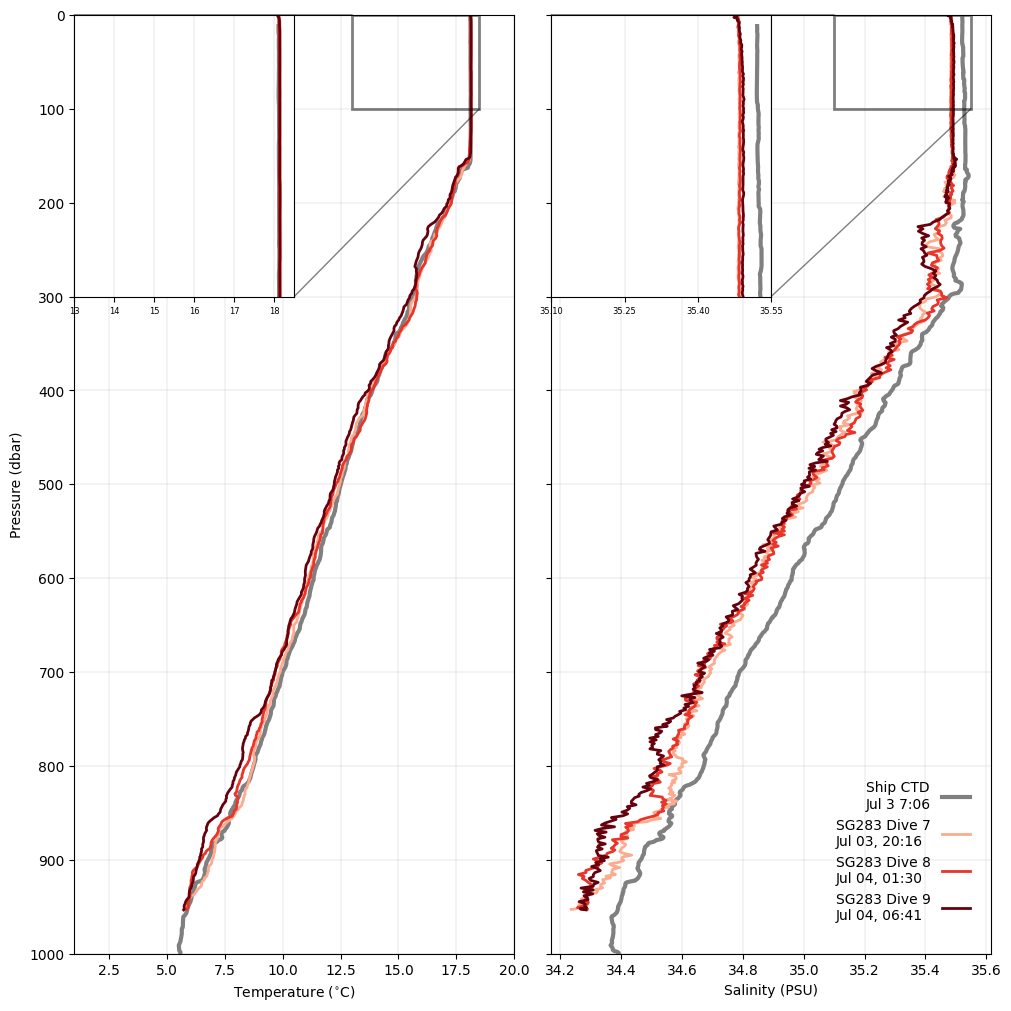

In [199]:

# Choosing some colors for ploting
plot_dives = [7, 8, 9]  # all dives [1.  1.5 2.  2.5 3.  3.5 4.  4.5 5.  5.5 6.  6.5 7.  7.5 8.  8.5 9.  9.5]
colormap_name = 'Reds'
num_colors = len(plot_dives)
cmap = plt.cm.get_cmap(colormap_name)
color_indices = np.linspace(0.3, 1, num_colors)
dc = [cmap(i) for i in color_indices]

# Define the dive indices to iterate over -> 13 is the first profile we have to 1000 m

# ----------------------------------------
# Getting the lables for each profile -> time legend
legend_times = []
for ind in plot_dives:
    # 1. Get the minimum time as an xarray DataArray
    first_time_da = gl.where(gl.dives == ind).dropna("ctd_data_point").ctd_time_dt64.mean()
    
    # 2. Extract the underlying NumPy scalar value
    time_scalar = first_time_da.values.item() 
    
    # 3. Check if the value is a valid time (i.e., not Not a Time/NaN)
    # np.isnat checks if a numpy datetime object is NaT
    if pd.notna(time_scalar):
        # Convert the numpy.datetime64/pandas NaT back to a pandas Timestamp for reliable formatting
        first_time_timestamp = pd.to_datetime(time_scalar)
        
        # Format the time (e.g., 'Sep 17, 10:00')
        legend_times.append(f"SG283 Dive {ind}\n"+first_time_timestamp.strftime('%b %d, %H:%M'))
    else:
        # Handle cases where the dive has no associated time (e.g., all times were null)
        legend_times.append('No Data Time')

# Combine ship label and time labels for the final legend 
all_labels = ['Ship CTD\nJul 3 7:06'] + legend_times #  2026-07-01T17:13:39.56
# ----------------------------------------

# Figure begins here! ----------------------------------------
fig, [ax, bx] = plt.subplots(1, 2, figsize=(10, 10), constrained_layout=True, sharey=True)

# --- ax: Temperature Profile (Main Plot) ---
# Pass is_main_plot=True to collect handles
all_handles = plot_profiles(ax, temp_down, -press_down, 'temperature', plot_dives, legend_times, gl, dc, is_main_plot=True)
# plot_profiles2(ax, temp_down, -press_down, glider_temp, glider_pres)
ax.set_ylim(-1000,0) 
ax.set_xlim(1,20)
ax.set_yticks(np.arange(-1000,100,100),labels=np.arange(1000,-100,-100))
ax.set_xlabel(r'Temperature ($^{\circ}$C)')
ax.set_ylabel('Pressure (dbar)')
ax.grid(lw=0.2)
# Adding legend to ax (Temperature)
bx.legend(
    all_handles, 
    all_labels, 
    #title='Profile Start Time',
    loc='lower right', 
    bbox_to_anchor=(0.98, 0.02), # Near the bottom-right corner of the plot area
    fontsize=10,
    frameon=False,
    markerfirst=False
    
)
ax_zoom = ax.inset_axes([0.000, 0.7, 0.5, 0.3]) 
all_handles = plot_profiles(ax_zoom, temp_down, -press_down, 'temperature', plot_dives, legend_times, gl, dc, is_main_plot=True)

ax_zoom.set_ylim(-100, 0)
ax_zoom.set_xlim(13, 18.5)
ax_zoom.set_xticks(np.arange(13, 18.5,1))
ax_zoom.grid(lw=0.2)
ax_zoom.set_yticks([])
ax.indicate_inset_zoom(ax_zoom,edgecolor="k",lw=2)
ax_zoom.tick_params(axis='x', labelsize=6)
ax_zoom.tick_params(axis='y', labelsize=6)
plot_profiles(bx, sal_down, -press_down, 'salinity',  plot_dives, legend_times, gl, dc, is_main_plot=True) # No need to collect handles here
bx.set_xlabel(r'Salinity (PSU)')
bx.grid(lw=0.2)

# --- bx inset: Salinity Zoom (0-100m) ---
bx_zoom = bx.inset_axes([0.000, 0.7, 0.5, 0.3]) 
plot_profiles(bx_zoom, sal_down, -press_down, 'salinity',  plot_dives, legend_times, gl, dc, is_main_plot=True)

bx_zoom.set_ylim(-100, 0)
bx_zoom.set_xlim(35.1, 35.55)
bx_zoom.set_xticks(np.arange(35.1, 35.56,0.15))
bx_zoom.tick_params(axis='x', labelsize=6)
bx_zoom.tick_params(axis='y', labelsize=6)
bx_zoom.grid(lw=0.2)
bx_zoom.set_yticks([])
bx.indicate_inset_zoom(bx_zoom,edgecolor="k",lw=2)


In [183]:
temp_interp = xr.DataArray(
    glider_temp.values,
    dims="ctd_pressure",
    coords={"ctd_pressure": glider_pres.values}
).interp(
    ctd_pressure=press_down
)

/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_56345/3359296654.py:21: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(
/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_56345/3359296654.py:30: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  glider_line = ax.scatter(
/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_56345/3359296654.py:21: UserWarning: *c* argument looks like a single num

Text(0, 0.5, 'Temperature SG ($^{\\circ}$C)')

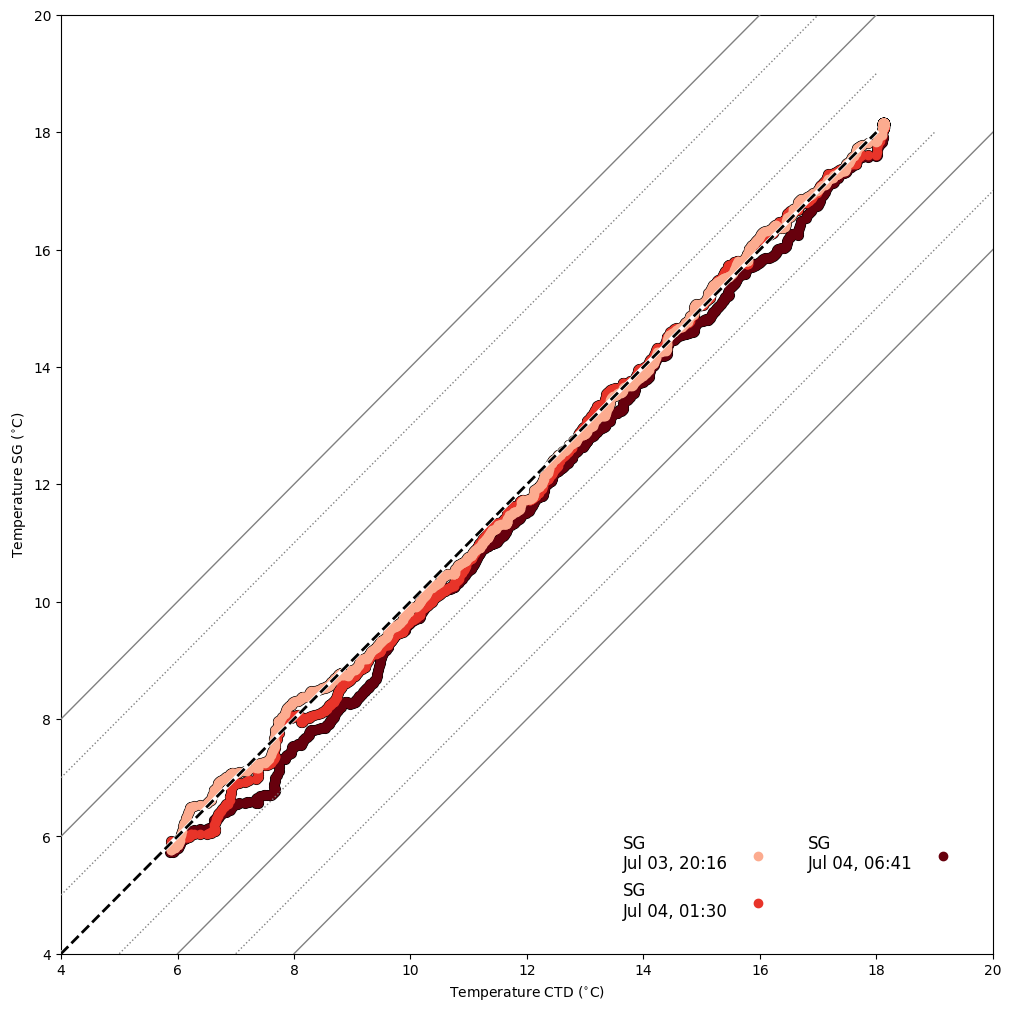

In [198]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10), constrained_layout=True, sharey=True)
    
# Glider Profiles
glider_handles = []
hmp=len(plot_dives)
for i, ind in enumerate(range(0,hmp)):
    ind = plot_dives[i]
    glider_temp = gl['temperature'].where(gl.dives == ind, drop=True)
    glider_sal = gl['salinity'].where(gl.dives == ind, drop=True)
    glider_pres = gl.ctd_pressure.where(gl.dives == ind, drop=True)
    temp_interp = xr.DataArray(
        glider_temp.values,
        dims="ctd_pressure",
        coords={"ctd_pressure": glider_pres.values}
    ).interp(
        ctd_pressure=press_down
    )
    # Use a label only if it's the main plot for legend handles
    label_text = legend_times[i]
    
    ax.scatter(
        temp_down,
        # ds_bin.isel(profile=7).temperature_binned,
        temp_interp,
        edgecolor='k',
        lw=2, 
        c=dc[i]
        # label=label_text
    )
    glider_line = ax.scatter(
        temp_down,
        # ds_bin.temperature_binned[:,ind],
        temp_interp,
        zorder=25-ind,
        c=dc[i]
    )
    glider_handles.append(glider_line)

ax.plot([4,18],[4,18],'w',ls='-',lw=3,zorder=100)
ax.plot([4,18],[4,18],'k',ls='--',lw=2,zorder=101)

ax.plot([5,19],[4,18],'.5',ls=':',lw=1, zorder=101)
ax.plot([6,20],[4,18],'.5',ls='-',lw=1, zorder=101)
ax.plot([7,21],[4,18],'.5',ls=':',lw=1, zorder=101)
ax.plot([8,22],[4,18],'.5',ls='-',lw=1, zorder=101)

ax.plot([4,18],[5,19],'.5',ls=':',lw=1, zorder=101)
ax.plot([4,18],[6,20],'.5',ls='-',lw=1, zorder=101)
ax.plot([4,18],[7,21],'.5',ls=':',lw=1, zorder=101)
ax.plot([4,18],[8,22],'.5',ls='-',lw=1, zorder=101)


ax.set_xlim(4,20)
ax.set_ylim(4,20)

# 3. Adding legend to ax (Temperature)
ax.legend(
    glider_handles, 
    legend_times, 
    ncol=2,
    #title='Profile Start Time',
    loc='lower right', 
    bbox_to_anchor=(0.98, 0.02), # Near the bottom-right corner of the plot area
    fontsize=12,
    frameon=False,
    markerfirst=False
    
)

ax.set_xlabel(r"Temperature CTD ($^{\circ}$C)")
ax.set_ylabel(r"Temperature SG ($^{\circ}$C)")


All temperature profiles:
Bias: -0.14753186687856598
RMSE: 0.25620186464264133
R²: 0.9977854342074349
N points: 2848


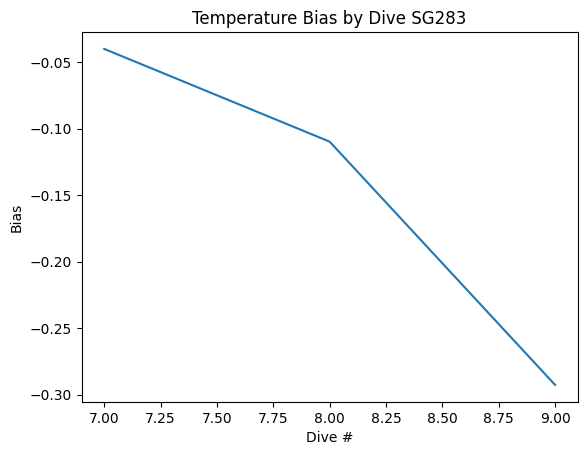

In [185]:
from scipy.stats import linregress
import numpy as np

all_glider_temp = []
all_ctd_temp = []
biases = []
rmses = []
glider_handles = []
for i, ind in enumerate(plot_dives):

    glider_temp = gl['temperature'].where(gl.dives == ind, drop=True)
    glider_pres = gl['ctd_pressure'].where(gl.dives == ind, drop=True)

    # sort pressure (important because glider pressure is not monotonic)
    sort_idx = np.argsort(glider_pres.values)

    glider_pres = glider_pres.values[sort_idx]
    glider_temp = glider_temp.values[sort_idx]

    # interpolate onto CTD pressure grid
    temp_interp = xr.DataArray(
        glider_temp,
        dims="ctd_pressure",
        coords={"ctd_pressure": glider_pres}
    ).interp(
        ctd_pressure=press_down
    )

    # store for statistics
    mask = np.isfinite(temp_interp.values) & np.isfinite(temp_down)

    all_glider_temp.append(temp_interp.values[mask])
    all_ctd_temp.append(temp_down[mask])
    biases.append(np.nanmean(temp_interp.values[mask] - temp_down[mask]))
    rmses.append(np.sqrt(np.mean(temp_interp.values[mask] - temp_down[mask])**2))

# concatenate all profiles
x = np.concatenate(all_ctd_temp)       # CTD
y = np.concatenate(all_glider_temp)    # glider

plt.plot(plot_dives, biases)
plt.title("Temperature Bias by Dive SG283")
plt.xlabel("Dive #")
plt.ylabel("Bias")
# statistics
slope, intercept, r_value, p_value, std_err = linregress(x, y)

r2 = r_value**2
rmse = np.sqrt(np.mean((y-x)**2))
bias = np.mean(y-x)

print("All temperature profiles:")
print("Bias:", bias)
print("RMSE:", rmse)
print("R²:", r2)
print("N points:", len(x))

7
8
9


Text(0, 0.5, 'Salinity SG (PSU)')

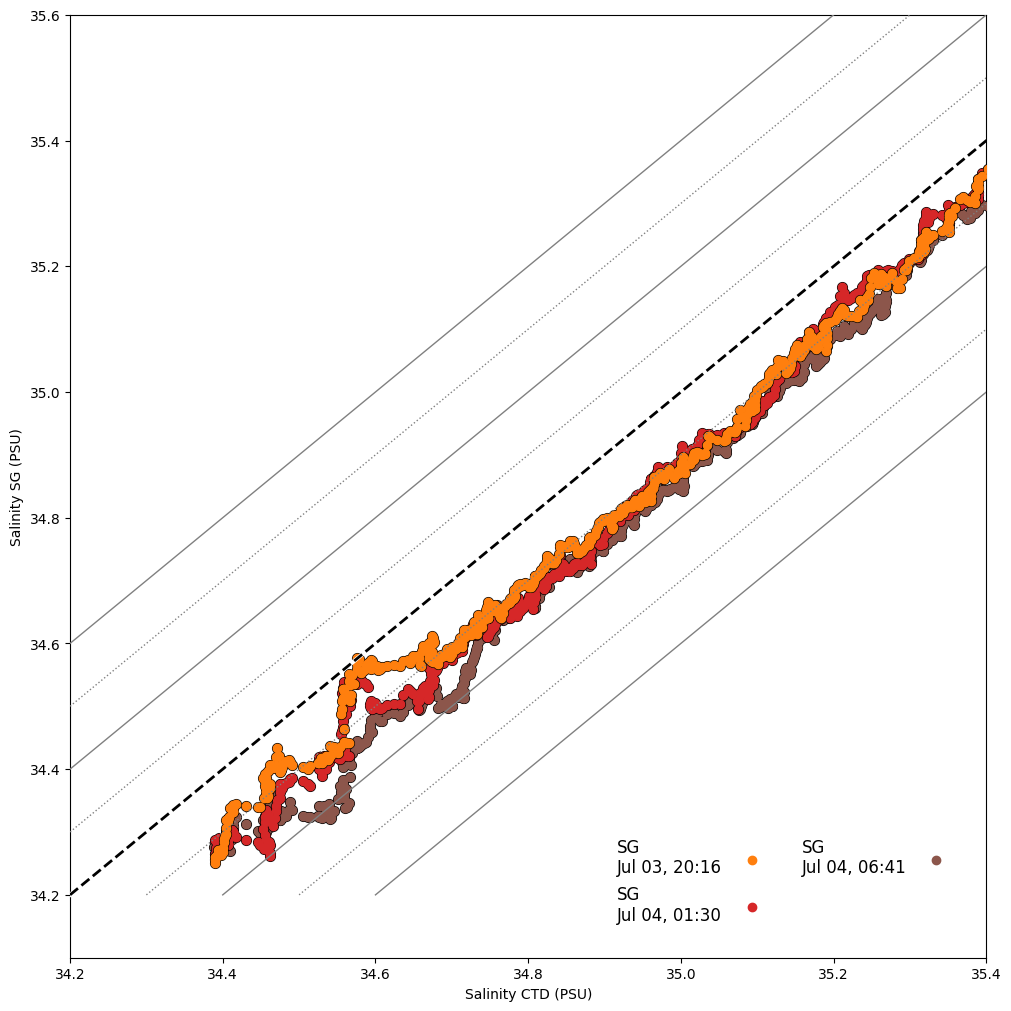

In [186]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10), constrained_layout=True, sharey=True)
    
# Glider Profiles
glider_handles = []
# hmp=1
for i, ind in enumerate(range(0,hmp)):
    ind = plot_dives[i]
    print(ind)
    glider_sal = gl['salinity'].where(gl.dives == ind, drop=True)
    glider_pres = gl.ctd_pressure.where(gl.dives == ind, drop=True)
    sal_interp = xr.DataArray(
        glider_sal.values,
        dims="ctd_pressure",
        coords={"ctd_pressure": glider_pres.values}
    ).interp(
        ctd_pressure=press_down
    )
    # Use a label only if it's the main plot for legend handles
    label_text = legend_times[i]
    
    ax.scatter(
        sal_down,
        # ds_bin.salinity_binned[:,ind],
        sal_interp,
        zorder=25-ind,
        edgecolor='k',
        lw=2, 
        # label=label_text
    )
    glider_line = ax.scatter(
        sal_down,
        # ds_bin.salinity_binned[:,ind],
        sal_interp,
        zorder=25-ind
    )
    glider_handles.append(glider_line)

ax.plot([34.2,35.6],[34.2,35.6],'w',ls='-',lw=3,zorder=100)
ax.plot([34.2,35.6],[34.2,35.6],'k',ls='--',lw=2,zorder=101)

ax.plot([34.3,35.7],[34.2,35.6],'.5',ls=':',lw=1, zorder=101)
ax.plot([34.4,35.8],[34.2,35.6],'.5',ls='-',lw=1, zorder=101)
ax.plot([34.5,35.9],[34.2,35.6],'.5',ls=':',lw=1, zorder=101)
ax.plot([34.6,36],[34.2,35.6],'.5',ls='-',lw=1, zorder=101)

ax.plot([34.2,35.6],[34.3,35.7],'.5',ls=':',lw=1, zorder=101)
ax.plot([34.2,35.6],[34.4,35.8],'.5',ls='-',lw=1, zorder=101)
ax.plot([34.2,35.6],[34.5,35.9],'.5',ls=':',lw=1, zorder=101)
ax.plot([34.2,35.6],[34.6,36],'.5',ls='-',lw=1, zorder=101)

ax.set_xlim(34.2,35.4)
ax.set_ylim(34.1,35.6)

# 3. Adding legend to ax (Temperature)
ax.legend(
    glider_handles, 
    legend_times, 
    ncol=2,
    #title='Profile Start Time',
    loc='lower right', 
    bbox_to_anchor=(0.98, 0.02), # Near the bottom-right corner of the plot area
    fontsize=12,
    frameon=False,
    markerfirst=False
    
)

ax.set_xlabel(r"Salinity CTD (PSU)")
ax.set_ylabel(r"Salinity SG (PSU)")



All temperature profiles:
Bias: -0.09088969135434619
RMSE: 0.09929936401143633
R²: 0.9945632897865002
N points: 2848


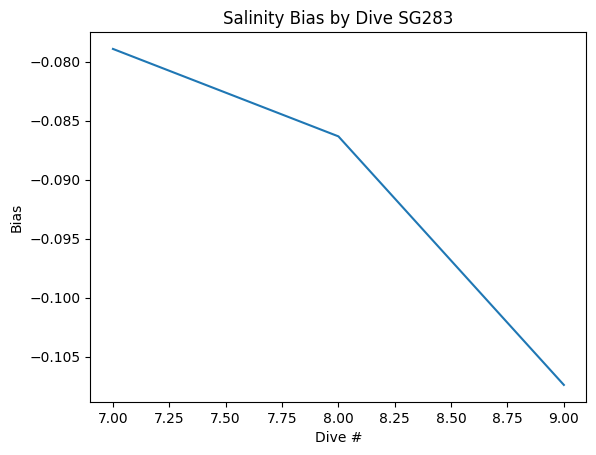

In [187]:
from scipy.stats import linregress
import numpy as np

all_glider_sal = []
all_ctd_sal = []
biases = []
rmses = []

for i, ind in enumerate(plot_dives):

    glider_sal= gl['salinity'].where(gl.dives == ind, drop=True)
    glider_pres = gl['ctd_pressure'].where(gl.dives == ind, drop=True)

    # sort pressure (important because glider pressure is not monotonic)
    sort_idx = np.argsort(glider_pres.values)

    glider_pres = glider_pres.values[sort_idx]
    glider_sal = glider_sal.values[sort_idx]

    # interpolate onto CTD pressure grid
    sal_interp = xr.DataArray(
        glider_sal,
        dims="ctd_pressure",
        coords={"ctd_pressure": glider_pres}
    ).interp(
        ctd_pressure=press_down
    )

    # store for statistics
    mask = np.isfinite(sal_interp.values) & np.isfinite(sal_down)

    all_glider_sal.append(sal_interp.values[mask])
    all_ctd_sal.append(sal_down[mask])
    biases.append(np.nanmean(sal_interp.values[mask] - sal_down[mask]))
    rmses.append(np.sqrt(np.mean(sal_interp.values[mask] - sal_down[mask])**2))

# concatenate all profiles # glider
plt.figure()
plt.plot(plot_dives, biases)
plt.title("Salinity Bias by Dive SG283")
plt.xlabel("Dive #")
plt.ylabel("Bias")
# concatenate all profiles
x = np.concatenate(all_ctd_sal)       # CTD
y = np.concatenate(all_glider_sal)    # glider


# statistics
slope, intercept, r_value, p_value, std_err = linregress(x, y)

r2 = r_value**2
rmse = np.sqrt(np.mean((y-x)**2))
bias = np.mean(y-x)

print("All temperature profiles:")
print("Bias:", bias)
print("RMSE:", rmse)
print("R²:", r2)
print("N points:", len(x))

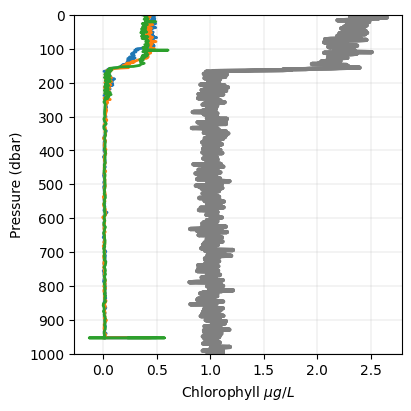

In [189]:
# Glider Profiles
glider_handles = []
plot_dives = [7, 8, 9]
fig, ax= plt.subplots(1, 1, figsize=(4, 4), constrained_layout=True, sharey=True)

hmp=len(plot_dives)
for ind in plot_dives:
    glider_temp = gl['temperature'].where(gl.dives == ind, drop=True)
    glider_sal = gl['salinity'].where(gl.dives == ind, drop=True)
    glider_pres = gl['ctd_pressure'].where(gl.dives == ind, drop=True)
    chl_time = chl['tridentebb700bb470chla470_time'].where(chl.dives==ind, drop=True)
    glider_chl = chl['tridentebb700bb470chla470_chla470'].where(chl.dives==ind, drop=True) # micrograms/liter
    glider_time = gl['ctd_time'].where(gl.dives==ind, drop=True)
    chl_pres = np.interp(chl_time, glider_time, glider_pres)
    # Use a label only if it's the main plot for legend handles
    label_text = legend_times[0]
    ship_line, = ax.plot(chloro_down, -press_down, '0.5', lw=3)

    glider_line, = ax.plot(
            glider_chl, 
            -chl_pres, 
            lw=2, 
            label=label_text
        ) 
# Glider Profiles
# glider_handles = []
# for i, ind in enumerate(plot_dives):
#     print("Plotting glider line")
#     glider_line, = current_ax.plot(
#         gl[gl_x_col].where(gl.dives == ind), 
#         -gl.ctd_pressure.where(gl.dives == ind), 
#         c=dc[i], 
#         lw=2, 
#         label=label_text
#     )
#     if is_main_plot:
#         glider_handles.append(glider_line)


# --- ax: Temperature Profile (Main Plot) ---
# Pass is_main_plot=True to collect handles
# all_handles = plot_profiles(ax, temp_down, -press_down, 'temperature', plot_dives, legend_times, gl, dc, is_main_plot=True)
# plot_profiles2(ax, temp_down, -press_down, glider_temp, glider_pres)
ax.set_ylim(-1000,0) 
# ax.set_xlim(1,20)
ax.set_yticks(np.arange(-1000,100,100),labels=np.arange(1000,-100,-100))
ax.set_xlabel(r'Chlorophyll $\mu g/L$')
ax.set_ylabel('Pressure (dbar)')
ax.grid(lw=0.2)
# Adding legend to ax (Temperature)

Text(0, 0.5, 'O2 SG (µmol/kg)')

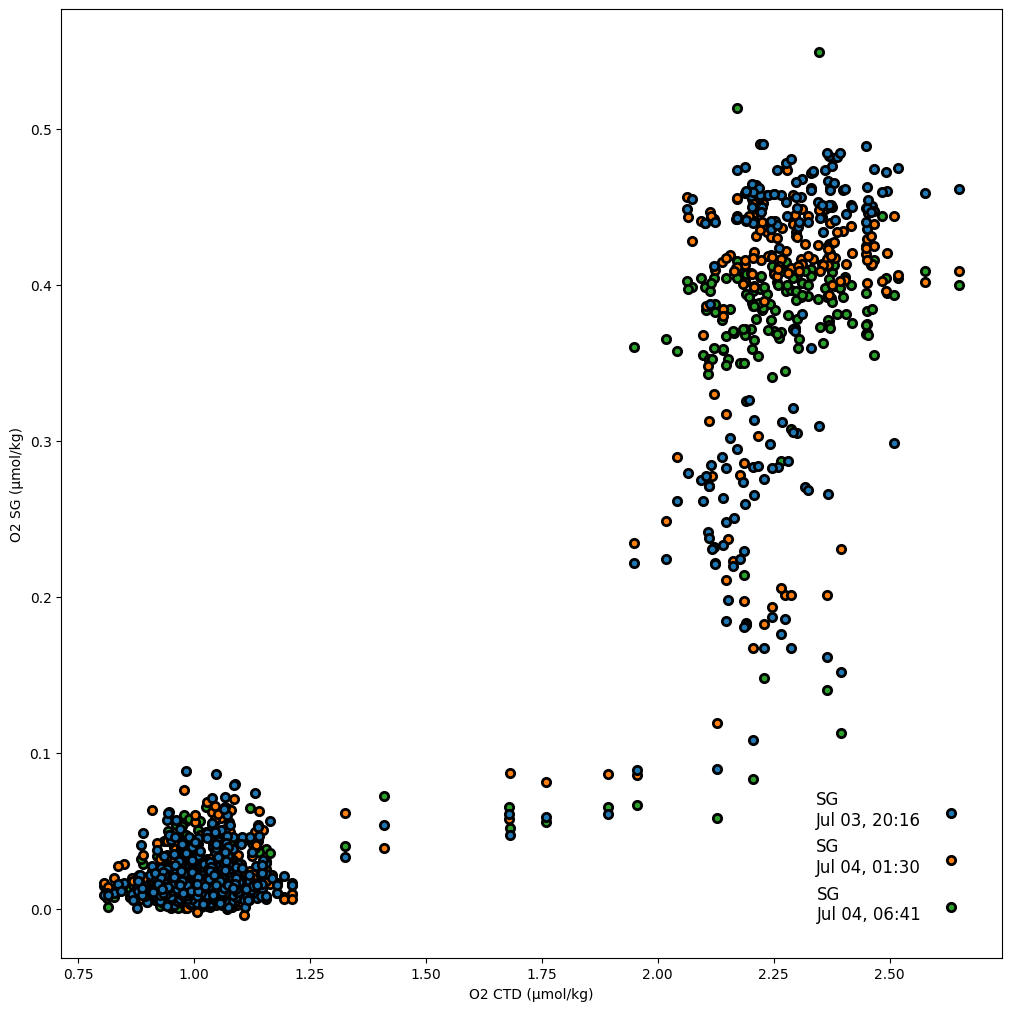

In [196]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10), constrained_layout=True, sharey=True)
    
# Glider Profiles
for i, ind in enumerate(range(0,hmp)):
    ind = plot_dives[i]
    glider_temp = gl['temperature'].where(gl.dives == ind, drop=True)
    glider_sal = gl['salinity'].where(gl.dives == ind, drop=True)
    glider_pres = gl['ctd_pressure'].where(gl.dives == ind, drop=True)
    chl_time = chl['tridentebb700bb470chla470_time'].where(chl.dives==ind, drop=True)
    glider_chl = chl['tridentebb700bb470chla470_chla470'].where(chl.dives==ind, drop=True) # micrograms/liter
    glider_time = gl['ctd_time'].where(gl.dives==ind, drop=True)
    chl_pres = np.interp(chl_time, glider_time, glider_pres)
    pressure, idx = np.unique(chl_pres, return_index=True)

    o2 = glider_chl.values[idx]

    o2_interp = xr.DataArray(
        o2,
        coords={"ctd_pressure": pressure},
        dims="ctd_pressure"
    ).interp(
        ctd_pressure=press_down
    )


    glider_handle = ax.scatter(
        chloro_down,
        # ds_bin.salinity_binned[:,ind],
        o2_interp,
        zorder=25-ind,
        edgecolor='k',
        lw=2, 
        # label=label_text
    )

# glider_handles.append(glider_line)

# ax.plot([34.2,35.6],[34.2,35.6],'w',ls='-',lw=3,zorder=100)
# ax.plot([34.2,35.6],[34.2,35.6],'k',ls='--',lw=2,zorder=101)

# ax.plot([34.3,35.7],[34.2,35.6],'.5',ls=':',lw=1, zorder=101)
# ax.plot([34.4,35.8],[34.2,35.6],'.5',ls='-',lw=1, zorder=101)
# ax.plot([34.5,35.9],[34.2,35.6],'.5',ls=':',lw=1, zorder=101)
# ax.plot([34.6,36],[34.2,35.6],'.5',ls='-',lw=1, zorder=101)

# ax.plot([34.2,35.6],[34.3,35.7],'.5',ls=':',lw=1, zorder=101)
# ax.plot([34.2,35.6],[34.4,35.8],'.5',ls='-',lw=1, zorder=101)
# ax.plot([34.2,35.6],[34.5,35.9],'.5',ls=':',lw=1, zorder=101)
# ax.plot([34.2,35.6],[34.6,36],'.5',ls='-',lw=1, zorder=101)

# ax.set_xlim(34.2,35.4)
# ax.set_ylim(34.1,35.6)

# 3. Adding legend to ax (Temperature)
ax.legend(
    legend_times, 
    #title='Profile Start Time',
    loc='lower right', 
    bbox_to_anchor=(0.98, 0.02), # Near the bottom-right corner of the plot area
    fontsize=12,
    frameon=False,
    markerfirst=False
    
)

ax.set_xlabel(r"O2 CTD (µmol/kg)")
ax.set_ylabel(r"O2 SG (µmol/kg)")



/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_56345/837489767.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap(colormap_name)


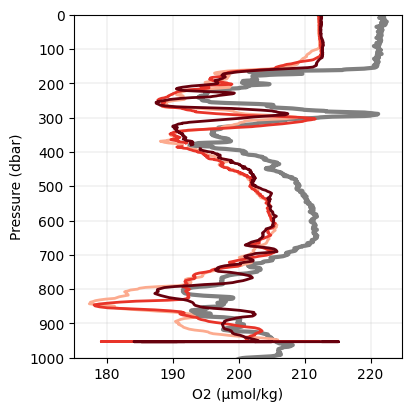

In [190]:
# Glider Profiles
glider_handles = []
plot_dives = [7.,  8., 9.] 
num_colors = len(plot_dives)
cmap = plt.cm.get_cmap(colormap_name)
color_indices = np.linspace(0.3, 1, num_colors)
dc = [cmap(i) for i in color_indices]
hmp=len(plot_dives)
fig, ax= plt.subplots(1, 1, figsize=(4, 4), constrained_layout=True, sharey=True)
ctd_o2_umolkg = o2_down * 44.66
ship_line, = ax.plot(ctd_o2_umolkg, -press_down, '0.5', lw=3)
for i, ind in enumerate(range(0,hmp)):
    ind = plot_dives[i]
    glider_temp = gl['temperature'].where(gl.dives == ind, drop=True)
    glider_sal = gl['salinity'].where(gl.dives == ind, drop=True)
    glider_pres = gl['ctd_pressure'].where(gl.dives == ind, drop=True)
    ox_time = ox['aa4831_time'].where(ox.dives==ind, drop=True)
    glider_ox =ox['aanderaa4831_instrument_dissolved_oxygen'].where(ox.dives==ind, drop=True) # micrograms/liter
    # glider_ox = glider_ox.where(glider_ox >= 0)
    
    glider_time = gl['ctd_time'].where(gl.dives==ind, drop=True)
    ox_pres = np.interp(ox_time, glider_time, glider_pres)
    # Use a label only if it's the main plot for legend handles
    label_text = legend_times[0]

   
    glider_ox = glider_ox.where(glider_ox >= 0)
    glider_line, = ax.plot(
            glider_ox, 
            -ox_pres, 
            lw=2, 
            c=dc[i],
            label=label_text
        ) 
ax.set_ylim(-1000,0) 
# ax.set_xlim(1,20)
ax.set_yticks(np.arange(-1000,100,100),labels=np.arange(1000,-100,-100))
ax.set_xlabel(r'O2 (µmol/kg)')
ax.set_ylabel('Pressure (dbar)')
ax.grid(lw=0.2)
# Adding legend to ax (Temperature)

Text(0, 0.5, 'O2 SG (µmol/kg)')

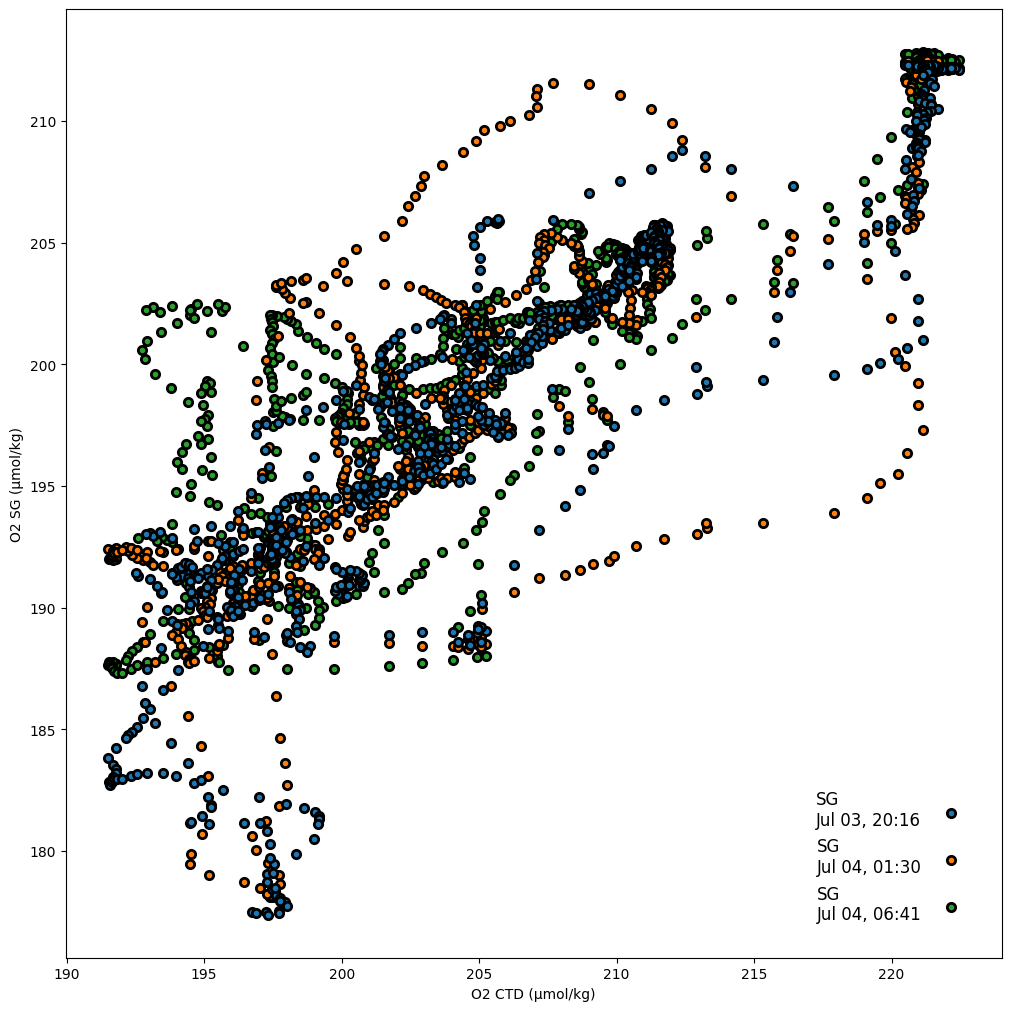

In [195]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10), constrained_layout=True, sharey=True)
    
# Glider Profiles
for i, ind in enumerate(range(0,hmp)):
    ind = plot_dives[i]
    glider_pres = gl['ctd_pressure'].where(gl.dives == ind, drop=True)
    ox_time = ox['aa4831_time'].where(ox.dives==ind, drop=True)
    glider_ox =ox['aanderaa4831_instrument_dissolved_oxygen'].where(ox.dives==ind, drop=True) # micrograms/liter
    glider_time = gl['ctd_time'].where(gl.dives==ind, drop=True)
    ox_pres = np.interp(ox_time, glider_time, glider_pres)
    glider_ox = glider_ox.where(glider_ox >= 0)
    pressure, idx = np.unique(ox_pres, return_index=True)

    o2 = glider_ox.values[idx]

    o2_interp = xr.DataArray(
        o2,
        coords={"ctd_pressure": pressure},
        dims="ctd_pressure"
    ).interp(
        ctd_pressure=press_down
    )


    glider_handle = ax.scatter(
        ctd_o2_umolkg,
        # ds_bin.salinity_binned[:,ind],
        o2_interp,
        zorder=25-ind,
        edgecolor='k',
        lw=2, 
        # label=label_text
    )

# glider_handles.append(glider_line)

# ax.plot([34.2,35.6],[34.2,35.6],'w',ls='-',lw=3,zorder=100)
# ax.plot([34.2,35.6],[34.2,35.6],'k',ls='--',lw=2,zorder=101)

# ax.plot([34.3,35.7],[34.2,35.6],'.5',ls=':',lw=1, zorder=101)
# ax.plot([34.4,35.8],[34.2,35.6],'.5',ls='-',lw=1, zorder=101)
# ax.plot([34.5,35.9],[34.2,35.6],'.5',ls=':',lw=1, zorder=101)
# ax.plot([34.6,36],[34.2,35.6],'.5',ls='-',lw=1, zorder=101)

# ax.plot([34.2,35.6],[34.3,35.7],'.5',ls=':',lw=1, zorder=101)
# ax.plot([34.2,35.6],[34.4,35.8],'.5',ls='-',lw=1, zorder=101)
# ax.plot([34.2,35.6],[34.5,35.9],'.5',ls=':',lw=1, zorder=101)
# ax.plot([34.2,35.6],[34.6,36],'.5',ls='-',lw=1, zorder=101)

# ax.set_xlim(34.2,35.4)
# ax.set_ylim(34.1,35.6)

# 3. Adding legend to ax (Temperature)
ax.legend(
    legend_times, 
    #title='Profile Start Time',
    loc='lower right', 
    bbox_to_anchor=(0.98, 0.02), # Near the bottom-right corner of the plot area
    fontsize=12,
    frameon=False,
    markerfirst=False
    
)

ax.set_xlabel(r"O2 CTD (µmol/kg)")
ax.set_ylabel(r"O2 SG (µmol/kg)")



All temperature profiles:
Bias: 191.9758750667639
RMSE: 195.26759852997947
R²: 0.10274773234779956
N points: 2848


/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_56345/2247211491.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap(colormap_name)


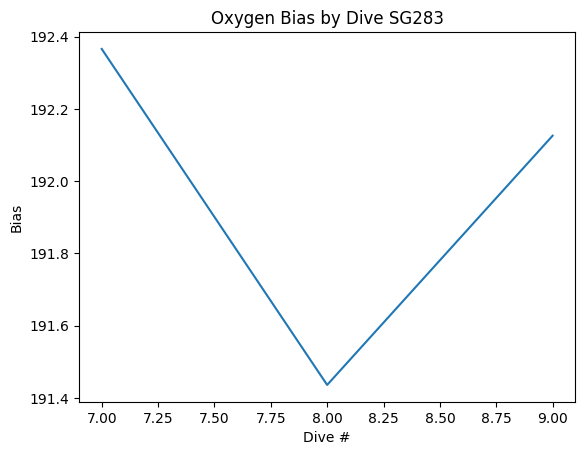

In [192]:
from scipy.stats import linregress
import numpy as np

all_glider_sal = []
all_ctd_sal = []
biases = []
rmses = []
plot_dives = [7.,  8., 9.] 
num_colors = len(plot_dives)
cmap = plt.cm.get_cmap(colormap_name)
color_indices = np.linspace(0.3, 1, num_colors)
dc = [cmap(i) for i in color_indices]
hmp=len(plot_dives)

for i, ind in enumerate(range(0,hmp)):
    ind = plot_dives[i]
    glider_temp = gl['temperature'].where(gl.dives == ind, drop=True)
    glider_sal = gl['salinity'].where(gl.dives == ind, drop=True)
    glider_pres = gl['ctd_pressure'].where(gl.dives == ind, drop=True)
    ox_time = ox['aa4831_time'].where(ox.dives==ind, drop=True)
    glider_ox =ox['aanderaa4831_instrument_dissolved_oxygen'].where(ox.dives==ind, drop=True) # micrograms/liter
    # glider_ox = glider_ox.where(glider_ox >= 0)
    glider_time = gl['ctd_time'].where(gl.dives==ind, drop=True)
    ox_pres = np.interp(ox_time, glider_time, glider_pres)

    pressure, idx = np.unique(ox_pres, return_index=True)

    o2 = glider_ox.values[idx]

    o2_interp = xr.DataArray(
        o2,
        coords={"ctd_pressure": pressure},
        dims="ctd_pressure"
    ).interp(
        ctd_pressure=press_down
    )

    # sort pressure (important because glider pressure is not monotonic)

    # store for statistics
    mask = np.isfinite(o2_interp.values) & np.isfinite(o2_down)

    all_glider_sal.append(o2_interp.values[mask])
    all_ctd_sal.append(o2_down[mask])
    biases.append(np.nanmean(o2_interp.values[mask] - o2_down[mask]))
    rmses.append(np.sqrt(np.mean(o2_interp.values[mask] - o2_down[mask])**2))

# concatenate all profiles # glider
plt.figure()
plt.plot(plot_dives, biases)
plt.title("Oxygen Bias by Dive SG283")
plt.xlabel("Dive #")
plt.ylabel("Bias")
# concatenate all profiles
x = np.concatenate(all_ctd_sal)       # CTD
y = np.concatenate(all_glider_sal)    # glider


# statistics
slope, intercept, r_value, p_value, std_err = linregress(x, y)

r2 = r_value**2
rmse = np.sqrt(np.mean((y-x)**2))
bias = np.mean(y-x)

print("All temperature profiles:")
print("Bias:", bias)
print("RMSE:", rmse)
print("R²:", r2)
print("N points:", len(x))

Text(0, 0.5, 'O2 SG (µmol/kg)')

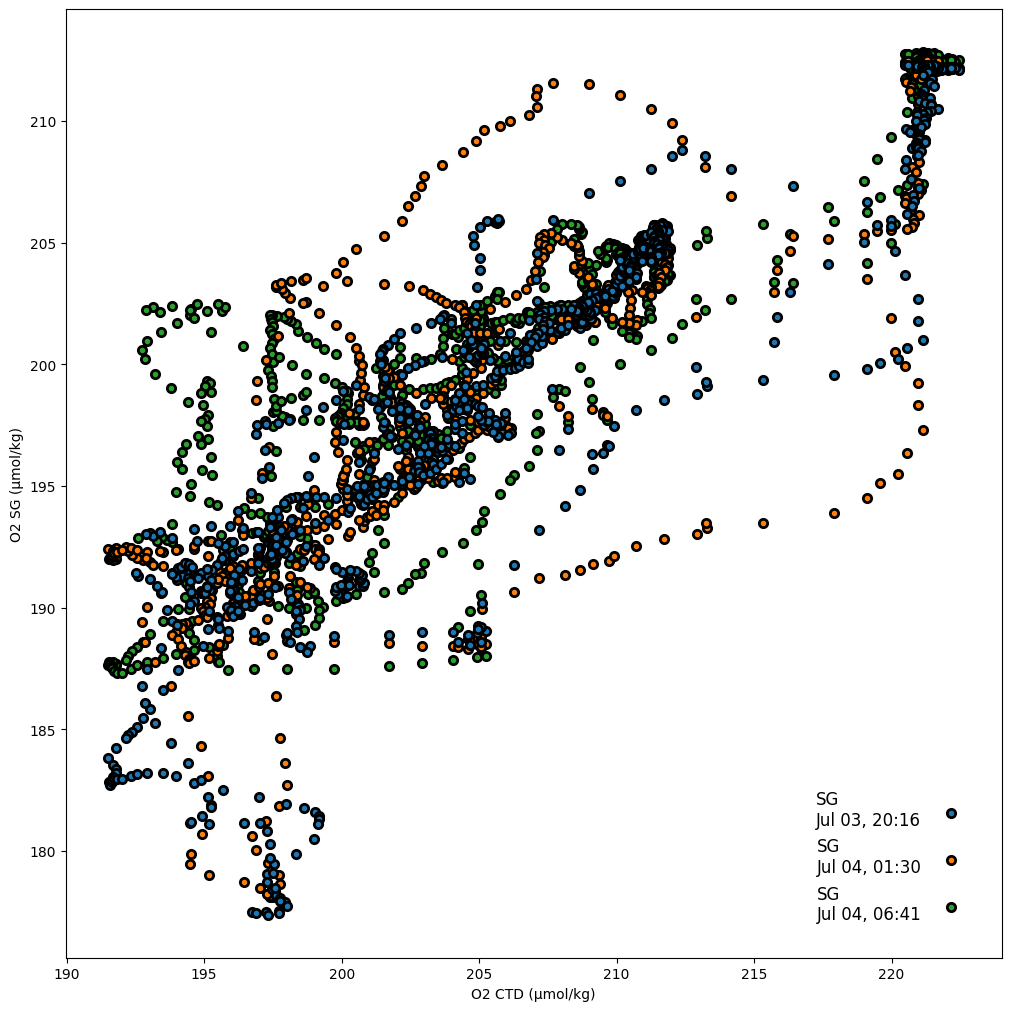